In [1]:
import sys, os, warnings
import numpy as np
import pandas as pd
import xarray as xr
from datetime import datetime

from utils.post_process import merge_bursts
from seasonal_burst.exhaustive_search import exhaustive_search_intra_period
import utils_notebook as utils

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots


import matplotlib.cm as cm
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
import matplotlib.colors as mcolors



import seaborn as sns
import random


In [2]:
def has_k_consecutive_above_threshold(arr, threshold, k):
    above_threshold = arr > threshold
    return np.any(np.convolve(above_threshold, np.ones(3, dtype=int), mode='valid') == k)

In [3]:
def sig_test(burst_set, start_year = 1974, end_year = 2023, N = 10000, lag=14, excludes = [1997]):
    ts_dates_normalized = ts_date_days.to_numpy().astype('datetime64[D]')
    date_to_index = {date: idx for idx, date in enumerate(ts_dates_normalized)}

    origin_sum = np.add.reduce(burst_set["mortality_14"])

    
    burst_dates = burst_set['date'].dt.floor('D').to_numpy().astype('datetime64[D]')
    indices = np.array([date_to_index.get(date) for date in burst_dates])
    # Remove invalid indices (if any)
    valid_mask = indices != None
    valid_indices = indices[valid_mask]
    # Prepare for simulation
    valid_burst_dates = burst_dates[valid_mask]
    day_month_pairs = pd.to_datetime(valid_burst_dates).strftime('%m-%d').tolist()
    years = np.arange(start_year, end_year+1)

    for year in excludes:
        if year in years:
            years = np.delete(years, np.where(years==year)[0][0])
        
    
    count = 0
    for i in range(N):
        rsum = 0.0
        for dm in day_month_pairs:
            ryear = random.choice(years)
            rdate = np.datetime64(f"{ryear}-{dm}", 'D')
            ind = date_to_index.get(rdate)
            if ind is not None:
                rsum += np.add.reduce(ts_mort_4[ind:ind+lag])
        if rsum >= origin_sum:
            count += 1

    return count, count / N

In [4]:
def bootstrap_diff_confidence_interval(burst_set, ts_date_days, ts_mort_4, num_bootstrap=10000, ci=95, start_year = 1998, end_year = 2023, lag=14):
    # Normalize date array
    ts_dates_normalized = ts_date_days.to_numpy().astype('datetime64[D]')
    date_to_index = {date: idx for idx, date in enumerate(ts_dates_normalized)}

    burst_dates = burst_set['date'].dt.floor('D').to_numpy().astype('datetime64[D]')
    years = np.arange(start_year, end_year+1)
    if start_year <= 1997 and end_year >= 1997:
        years = np.delete(years, np.where(years==1997)[0][0])
    n_years = len(years)
    N = len(burst_dates)
    diffs = np.zeros(N)

    for i, bdate in enumerate(burst_dates):
        ind = date_to_index[bdate]
        rate_y = np.add.reduce(ts_mort_4[ind:ind+lag])  # 14-day rate at burst year

        # Extract day and month
        month = pd.to_datetime(bdate).month
        day = pd.to_datetime(bdate).day

        rates_all_years = 0
        for y in years:
            comp_date = np.datetime64(f"{y}-{month:02}-{day:02}", 'D')
            ind_y = date_to_index.get(comp_date)
            rates_all_years += np.add.reduce(ts_mort_4[ind_y:ind_y+lag])
        
        
        avg_rate = rates_all_years / n_years
        diffs[i] = rate_y - avg_rate

    # Bootstrap: 10,000 means
    boot_means = np.array([
        np.mean(np.random.choice(diffs, size=N, replace=True))
        for _ in range(num_bootstrap)
    ])

    lower = np.percentile(boot_means, (100 - ci) / 2)
    upper = np.percentile(boot_means, 100 - (100 - ci) / 2)

    return {
        "boot_means": boot_means,
        "mean_diff": np.mean(diffs),
        f"{ci}%_CI": (lower, upper),
        "diffs": diffs.tolist()
    }

def bootstrap_diff_confidence_interval2(burst_set, ts_date_days, ts_mort_4, num_bootstrap=10000, ci=95, start_year=1998, end_year=2023, lag=14):
    # Normalize date array
    ts_dates_normalized = ts_date_days.to_numpy().astype('datetime64[D]')
    date_to_index = {date: idx for idx, date in enumerate(ts_dates_normalized)}

    burst_dates = burst_set['date'].dt.floor('D').to_numpy().astype('datetime64[D]')
    years = np.arange(start_year, end_year + 1)
    if start_year <= 1997 and end_year >= 1997:
        years = np.delete(years, np.where(years == 1997)[0][0])
    n_years = len(years)
    N = len(burst_dates)
    diffs = np.zeros(N)
    percent_increases = np.zeros(N)

    for i, bdate in enumerate(burst_dates):
        ind = date_to_index[bdate]
        rate_y = np.add.reduce(ts_mort_4[ind:ind + lag])  # 14-day rate at burst year

        # Extract day and month
        month = pd.to_datetime(bdate).month
        day = pd.to_datetime(bdate).day

        rates_all_years = 0
        for y in years:
            comp_date = np.datetime64(f"{y}-{month:02}-{day:02}", 'D')
            ind_y = date_to_index.get(comp_date)
            rates_all_years += np.add.reduce(ts_mort_4[ind_y:ind_y + lag])

        avg_rate = rates_all_years / n_years
        diffs[i] = rate_y - avg_rate
        percent_increases[i] = ((rate_y - avg_rate) / avg_rate) * 100

    # Bootstrap: 10,000 means
    boot_means = np.array([
        np.mean(np.random.choice(diffs, size=N, replace=True))
        for _ in range(num_bootstrap)
    ])

    lower = np.percentile(boot_means, (100 - ci) / 2)
    upper = np.percentile(boot_means, 100 - (100 - ci) / 2)

    avg_percent_increase = np.average(percent_increases)
    med_percent_increase = np.median(percent_increases)

    return {
        "boot_means": boot_means,
        "mean_diff": np.mean(diffs),
        f"{ci}%_CI": (lower, upper),
        "diffs": diffs.tolist(),
        "avg_percent_increase": avg_percent_increase,
        "med_percent_increase": med_percent_increase
    }

In [5]:
start_year = 1975
end_year = 2023
n_year = end_year - start_year + 1

len_year = 92 * 24

ds = xr.open_dataset("wgbt_era5_Paris_1974-2023jja.nc")
ts_wbgt = ds.wbgt.values.ravel().astype(np.float64)
ts_date = pd.DatetimeIndex(ds.time.values)
ts_tas = xr.open_dataset("ta_era5_Paris_1974-2023jja.nc").t2m.values.ravel().astype(np.float64) - 273.15
ts_mort = np.load("death_rate_jja.npy").astype(np.float64)[(start_year-1975)*92:] * 10000

mask = (ts_date.year >= start_year) & (ts_date.year <= end_year)
ts_wbgt = ts_wbgt[mask]
ts_tas = ts_tas[mask]
ts_date = ts_date[mask]


ts_date_days = pd.date_range(f'01-Jan-{start_year}', f'31-Dec-{end_year}', freq='D')
ts_date_days = ts_date_days[ts_date_days.month.isin([6, 7, 8, 9])]


In [6]:
data = {'date': ts_date, 'wbgt': (ts_wbgt >= 28).astype(int), 'tas': (ts_tas >= 30).astype(int)}
df =  pd.DataFrame(data)

In [7]:
mort_start_year = 1975
df = df[df['date'].dt.year >= mort_start_year]

df_daily = df.resample("D", on="date").sum().reset_index().dropna()
df_daily = df_daily[df_daily['date'].dt.month.isin([6, 7, 8])]

In [8]:
def compute_lag_mortality(burst_set, lag, mort_start_year):
    
    ts_date_days = pd.date_range(f'01-Jan-{mort_start_year}', '31-Dec-2023', freq='D')
    ts_date_days = ts_date_days[ts_date_days.month.isin([6, 7, 8, 9])]
    ts_dates_normalized = ts_date_days.to_numpy().astype('datetime64[D]')
    date_to_index = {date: idx for idx, date in enumerate(ts_dates_normalized)}
    # Normalize burst dates
    burst_dates = burst_set['date'].dt.floor('D').to_numpy().astype('datetime64[D]')
    indices = np.array([date_to_index.get(date) for date in burst_dates])

    # Remove invalid indices (if any)
    valid_mask = indices != None
    valid_indices = indices[valid_mask]
    mortality_14 = np.array([np.add.reduce(ts_mort_4[i:i+lag]) for i in valid_indices])
    return mortality_14

def compute_average_lag_mortality(burst_set, lag):
    ts_dates_normalized = ts_date_days.to_numpy().astype('datetime64[D]')
    date_to_index = {date: idx for idx, date in enumerate(ts_dates_normalized)}
    years = np.arange(1998, 2024)

    burst_dates = burst_set['date'].dt.floor('D').to_numpy().astype('datetime64[D]')
    avg_mortalities = []

    for bdate in burst_dates:
        dt = pd.to_datetime(bdate)
        m = dt.month
        d = dt.day

        values = []
        for y in years:
            try:
                rdate = np.datetime64(f"{y}-{m:02}-{d:02}", 'D')
                ind = date_to_index.get(rdate)
                if ind is not None:
                    values.append(np.sum(ts_mort_4[ind:ind+lag]))
            except:
                continue

        if values:
            avg_mortalities.append(np.mean(values))
        else:
            avg_mortalities.append(np.nan)

    return np.array(avg_mortalities)

In [9]:
ts_mort_4 = np.load("death_rate_jjas.npy").astype(np.float64) * 10000
ts_date_days = pd.date_range(f'01-Jan-{mort_start_year}', '31-Dec-2023', freq='D')
ts_date_days = ts_date_days[ts_date_days.month.isin([6, 7, 8, 9])]
df_daily['rate'] = ts_mort

burst_set_wbgt = df_daily[df_daily['wbgt'] >= 1].reset_index()
burst_set_wbgt['mortality_7'] = compute_lag_mortality( burst_set_wbgt, 7, mort_start_year)
burst_set_wbgt['mortality_14'] = compute_lag_mortality( burst_set_wbgt, 14, mort_start_year)
burst_set_wbgt['mortality_14_avr'] = compute_average_lag_mortality( burst_set_wbgt, 14)

burst_set_tas = df_daily[df_daily['tas'] >= 1].reset_index()
burst_set_tas['mortality_7'] = compute_lag_mortality( burst_set_tas, 7, mort_start_year)
burst_set_tas['mortality_14'] = compute_lag_mortality( burst_set_tas, 14, mort_start_year)
burst_set_tas['mortality_14_avr'] = compute_average_lag_mortality( burst_set_tas, 14)

In [10]:
count, p_value = sig_test(burst_set_wbgt, mort_start_year, 2023, lag=14)
print(f"Count: {count}, p-value {p_value}")

Count: 0, p-value 0.0


Average 1.105 [0.384, 1.925] 41.334% 6.357%


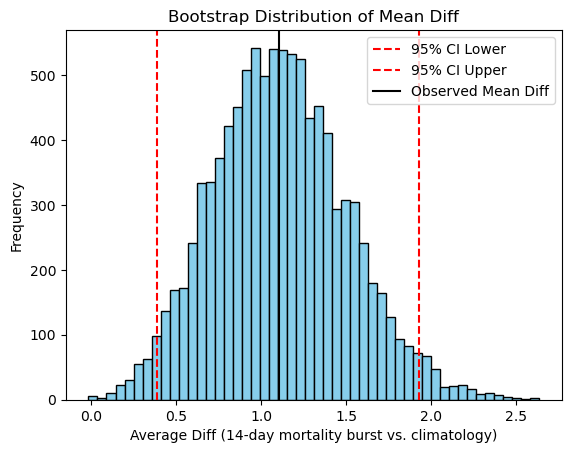

In [11]:
result = bootstrap_diff_confidence_interval2(burst_set_wbgt, ts_date_days, ts_mort_4, start_year=mort_start_year, lag=14)
print(f"Average {result['mean_diff']:.3f} [{result['95%_CI'][0]:.3f}, {result['95%_CI'][1]:.3f}] {result['avg_percent_increase']:.3f}% {result['med_percent_increase']:.3f}%" )

plt.hist(result['boot_means'], bins=50, color='skyblue', edgecolor='black')
plt.axvline(result['95%_CI'][0], color='red', linestyle='--', label='95% CI Lower')
plt.axvline(result['95%_CI'][1], color='red', linestyle='--', label='95% CI Upper')
plt.axvline(result['mean_diff'], color='black', linestyle='-', label='Observed Mean Diff')
plt.legend()
plt.title('Bootstrap Distribution of Mean Diff')
plt.xlabel('Average Diff (14-day mortality burst vs. climatology)')
plt.ylabel('Frequency')
plt.show()

In [12]:
burst_set_wbgt_excl = burst_set_wbgt[burst_set_wbgt['date'].dt.year != 2003]
count, p_value = sig_test(burst_set_wbgt_excl, lag=14, excludes=[1997, 2003])
print(f"Count: {count}, p-value {p_value}")

Count: 83, p-value 0.0083


Average 0.324 [0.121, 0.606] 12.290% 4.833%


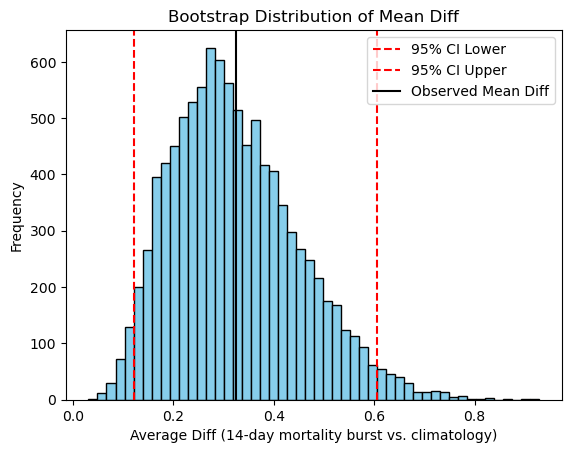

In [13]:
result = bootstrap_diff_confidence_interval2(burst_set_wbgt_excl, ts_date_days, ts_mort_4)
print(f"Average {result['mean_diff']:.3f} [{result['95%_CI'][0]:.3f}, {result['95%_CI'][1]:.3f}] {result['avg_percent_increase']:.3f}% {result['med_percent_increase']:.3f}%" )

plt.hist(result['boot_means'], bins=50, color='skyblue', edgecolor='black')
plt.axvline(result['95%_CI'][0], color='red', linestyle='--', label='95% CI Lower')
plt.axvline(result['95%_CI'][1], color='red', linestyle='--', label='95% CI Upper')
plt.axvline(result['mean_diff'], color='black', linestyle='-', label='Observed Mean Diff')
plt.legend()
plt.title('Bootstrap Distribution of Mean Diff')
plt.xlabel('Average Diff (14-day mortality burst vs. climatology)')
plt.ylabel('Frequency')
plt.show()

In [14]:
count, p_value = sig_test(burst_set_tas)
print(f"Count: {count}, p-value {p_value}")

Count: 0, p-value 0.0


In [15]:
burst_set_tas

,index,date,wbgt,tas,rate,mortality_7,mortality_14,mortality_14_avr
0,61,1975-08-01,0,3,0.262472,2.147498,3.829705,2.659850
1,62,1975-08-02,0,6,0.340021,2.225047,3.770052,2.644700
2,63,1975-08-03,0,8,0.304229,2.147498,3.597060,2.631638
3,64,1975-08-04,0,10,0.304229,2.010297,3.441962,2.632235
4,66,1975-08-06,0,3,0.280368,1.765721,3.251074,2.637694
...,...,...,...,...,...,...,...,...
314,17572,2023-07-11,0,5,0.225826,1.322696,2.520957,2.621098
315,17575,2023-07-14,0,3,0.248870,1.272000,2.557826,2.630596
316,17610,2023-08-18,0,1,0.142749,1.312372,2.666187,2.423441
317,17614,2023-08-22,0,1,0.170378,1.363025,2.767910,2.444696


In [16]:
burst_set_wbgt

,index,date,wbgt,tas,rate,mortality_7,mortality_14,mortality_14_avr
0,398,1976-07-03,1,7,0.482641,2.948817,4.985326,2.681899
1,5542,1990-08-03,1,10,0.227440,1.774034,3.102285,2.631638
2,6278,1992-08-08,2,9,0.223930,1.402992,2.824265,2.606452
3,7355,1995-07-21,7,9,0.290193,1.566120,3.430123,2.606901
4,8107,1997-08-11,1,5,0.302316,1.727520,3.347071,2.557713
5,8472,1998-08-11,2,9,0.222014,1.295834,2.487458,2.557713
6,9878,2002-06-17,5,10,0.199990,1.449926,2.836219,2.762636
7,10292,2003-08-05,5,10,0.294718,3.314444,7.712544,2.634058
8,10293,2003-08-06,7,10,0.281116,4.493316,7.599191,2.637694
9,10294,2003-08-07,7,10,0.480617,5.445482,7.508508,2.627941


Average 0.278 [0.211, 0.353] 20.785% 7.678%


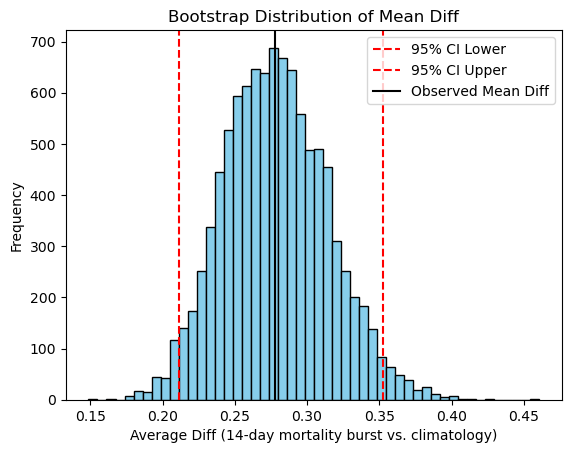

In [17]:
result = bootstrap_diff_confidence_interval2(burst_set_tas, ts_date_days, ts_mort_4, lag=7)
print(f"Average {result['mean_diff']:.3f} [{result['95%_CI'][0]:.3f}, {result['95%_CI'][1]:.3f}] {result['avg_percent_increase']:.3f}% {result['med_percent_increase']:.3f}%" )

plt.hist(result['boot_means'], bins=50, color='skyblue', edgecolor='black')
plt.axvline(result['95%_CI'][0], color='red', linestyle='--', label='95% CI Lower')
plt.axvline(result['95%_CI'][1], color='red', linestyle='--', label='95% CI Upper')
plt.axvline(result['mean_diff'], color='black', linestyle='-', label='Observed Mean Diff')
plt.legend()
plt.title('Bootstrap Distribution of Mean Diff')
plt.xlabel('Average Diff (14-day mortality burst vs. climatology)')
plt.ylabel('Frequency')
plt.show()

In [18]:
burst_set_tas_excl = burst_set_tas[burst_set_tas['date'].dt.year != 2003]
count, p_value = sig_test(burst_set_tas_excl, excludes=[1997, 2003])
print(f"Count: {count}, p-value {p_value}")

Count: 0, p-value 0.0


Average 0.185 [0.146, 0.226] 13.898% 7.277%


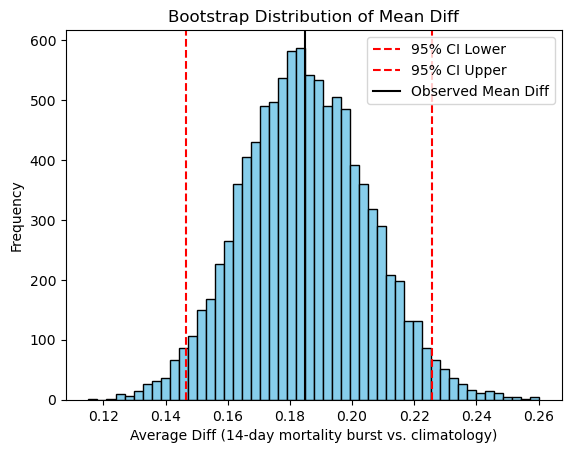

In [19]:
result = bootstrap_diff_confidence_interval2(burst_set_tas_excl, ts_date_days, ts_mort_4, lag=7)
print(f"Average {result['mean_diff']:.3f} [{result['95%_CI'][0]:.3f}, {result['95%_CI'][1]:.3f}] {result['avg_percent_increase']:.3f}% {result['med_percent_increase']:.3f}%" )


plt.hist(result['boot_means'], bins=50, color='skyblue', edgecolor='black')
plt.axvline(result['95%_CI'][0], color='red', linestyle='--', label='95% CI Lower')
plt.axvline(result['95%_CI'][1], color='red', linestyle='--', label='95% CI Upper')
plt.axvline(result['mean_diff'], color='black', linestyle='-', label='Observed Mean Diff')
plt.legend()
plt.title('Bootstrap Distribution of Mean Diff')
plt.xlabel('Average Diff (14-day mortality burst vs. climatology)')
plt.ylabel('Frequency')
plt.show()

In [20]:
increase = (burst_set_wbgt['mortality_14'] - burst_set_wbgt['mortality_14_avr'])/burst_set_wbgt['mortality_14_avr']*100
np.mean(increase), np.median(increase), np.percentile(increase, 10)

(47.33406374411768, 8.3566952171069, -0.029575900711645342)

In [21]:
increase = (burst_set_tas['mortality_14'] - burst_set_tas['mortality_14_avr'])/burst_set_tas['mortality_14_avr']*100
np.mean(increase), np.median(increase), np.percentile(increase, 30)

(15.506844579960006, 4.9896633053387935, 0.06675956915803988)